# Real Bridge Segmentation Evaluation & Visualization

This notebook evaluates the same checkpoints and metrics as `eval_exp2.ipynb` on the five JPGs annotated in the Labelbox NDJSON export. Labelbox `ImagePolygon` crack annotations are rasterized into binary masks.

For comparability with `eval_exp2.ipynb`, both images and masks are resized with the project's validation transform to `config.IMG_SIZE` (currently 448 x 448); the centerline tolerance is therefore in resized-image pixels. Whole-image resizing can discard fine details in high-resolution photos, so interpret these as same-pipeline comparison metrics, not full-resolution patch-inference scores.

The notebook computes per-model means, writes metrics to `experimenting/real_bridge_eval_exp2_metrics.csv`, and generates 4-panel visual crack overlays (Original Image, UNet, SegFormer Dice+Focal, and YOLO-seg) using full-resolution sliding-window patch inference.


In [2]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import csv
import json
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

from crack_seg import config
from crack_seg.data_handlers.transforms import val_transform
from crack_seg.predict import predict_with_patches
from crack_seg.utils.helpers import (
    load_model,
    create_red_overlay,
    predict_yolo_mask,
    warmup_gpu,
    predict_mask,
)
from crack_seg.utils.visualization import (
    plot_overlay_comparison,
    visualize_model_overlays,
)
from crack_seg.utils.metrics import (
    centerline_buffer_metrics,
    cldice_score,
    crack_orientation_mae,
    dice_coefficient,
    iou_score,
    pixel_accuracy,
    precision_score,
    recall_score,
    specificity_score,
)

BRIDGE_DIR = config.DATA_ROOT / "real_bridge_sample"
ANNOTATION_FILE = BRIDGE_DIR / "Export  project - Bridge_cracks - 10_26_2026.ndjson"
RESULTS_CSV = config.BASE_DIR / "experimenting" / "real_bridge_eval_exp2_metrics.csv"

SKELETON_METHOD = getattr(config, "SKELETON_METHOD", "lee")
TOLERANCE_PX = float(getattr(config, "CENTERLINE_TOLERANCE_PX", 20.0))
TOL_TAG = int(TOLERANCE_PX) if TOLERANCE_PX.is_integer() else f"{TOLERANCE_PX:.1f}"
OPEN_KERNEL_SIZE = 10
CLOSE_KERNEL_SIZE = 10
CLOSE_DILATE_ITERS = 5
CLOSE_ERODE_ITERS = 1
YOLO_CONFIDENCE = 0.25

if not BRIDGE_DIR.is_dir():
    raise FileNotFoundError(f"Bridge data directory not found: {BRIDGE_DIR}")
if not ANNOTATION_FILE.is_file():
    raise FileNotFoundError(f"Labelbox export not found: {ANNOTATION_FILE}")

print(f"Device: {config.DEVICE}")
print(f"Image/mask size: {config.IMG_SIZE}")
print(f"Centerline tolerance: {TOLERANCE_PX}px")


Device: cuda
Image/mask size: (448, 448)
Centerline tolerance: 20.0px


In [3]:
# Match each Labelbox external_id to the local JPG and rasterize its crack polygons.
records = [
    json.loads(line)
    for line in ANNOTATION_FILE.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
local_images = {
    path.name.casefold(): path
    for path in BRIDGE_DIR.iterdir()
    if path.is_file() and path.suffix.casefold() == ".jpg"
}
record_names = [record["data_row"]["external_id"] for record in records]
record_keys = [name.casefold() for name in record_names]

if len(record_keys) != len(set(record_keys)):
    raise ValueError("The Labelbox export contains duplicate image external_id values.")
missing_images = sorted(set(record_keys) - set(local_images))
unannotated_images = sorted(set(local_images) - set(record_keys))
if missing_images or unannotated_images:
    raise ValueError(
        "Local JPGs and Labelbox rows do not match. "
        f"Missing local files: {missing_images}; without labels: {unannotated_images}"
    )

bridge_samples = []
for record in records:
    image_name = record["data_row"]["external_id"]
    image_path = local_images[image_name.casefold()]
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    attributes = record.get("media_attributes", {})
    expected_size = (attributes.get("width"), attributes.get("height"))
    if expected_size != image.size:
        raise ValueError(
            f"Image size mismatch for {image_name}: local {image.size}, Labelbox {expected_size}"
        )

    objects = [
        obj
        for project in (record.get("projects") or {}).values()
        for label in project.get("labels", [])
        for obj in label.get("annotations", {}).get("objects", [])
        if str(obj.get("value", "")).casefold() == "cracks"
    ]
    if not objects:
        raise ValueError(f"No crack annotations found for {image_name}.")

    mask = Image.new("L", image.size, 0)
    draw = ImageDraw.Draw(mask)
    for obj in objects:
        if obj.get("annotation_kind") != "ImagePolygon":
            raise ValueError(
                f"Unsupported crack annotation for {image_name}: {obj.get('annotation_kind')}"
            )
        polygon = obj.get("polygon") or []
        if len(polygon) < 3:
            raise ValueError(f"Invalid crack polygon in {image_name}.")
        points = [(float(point["x"]), float(point["y"])) for point in polygon]
        points_array = np.asarray(points)
        if not np.isfinite(points_array).all():
            raise ValueError(f"Non-finite polygon coordinate in {image_name}.")
        if (
            (points_array[:, 0] < 0).any()
            or (points_array[:, 0] > width).any()
            or (points_array[:, 1] < 0).any()
            or (points_array[:, 1] > height).any()
        ):
            raise ValueError(f"Polygon coordinate outside image bounds in {image_name}.")
        draw.polygon([(round(x), round(y)) for x, y in points], fill=255)

    image_tensor, target = val_transform(image, mask)
    target = (target >= 0.5).float()
    if not target.any():
        raise ValueError(f"Crack mask is empty after resizing for {image_name}.")
    bridge_samples.append((image_name, image_path, image_tensor, target))
    print(f"{image_name}: {len(objects)} polygons, resized GT pixels={int(target.sum())}")

print(f"\nLoaded {len(bridge_samples)} annotated bridge images.")

2401-Mar-11-2021 (46).jpg: 19 polygons, resized GT pixels=2747
2401-Mar-11-2021 (47).jpg: 11 polygons, resized GT pixels=1519
2401-Mar-11-2021 (59).JPG: 19 polygons, resized GT pixels=2342
learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.jpg: 9 polygons, resized GT pixels=960
learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.jpg: 2 polygons, resized GT pixels=515

Loaded 5 annotated bridge images.


In [4]:
# Keep the same checkpoint set as eval_exp2.ipynb; unavailable checkpoints are skipped.
MODELS_TO_EVALUATE = {
    "UNet (NCCD-PF)": {
        "type": "unet",
        "path": config.CHECKPOINT_DIR / "unet_NCCD-PF_Dataset.pth",
    },
    "UNet (4 Datasets)": {
        "type": "unet",
        "path": config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth",
    },
    "SegFormer (4 Datasets)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth",
    },
    "SegFormer (Focal)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_focal.pth",
    },
    "SegFormer (Dice+Focal)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_dice_focal.pth",
    },
    "YOLO-seg (4 Datasets)": {
        "type": "yolo",
        "path": config.CHECKPOINT_DIR
        / "yolo_runs"
        / "yolo_seg_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pt",
    },
}

active_models = {
    name: info
    for name, info in MODELS_TO_EVALUATE.items()
    if Path(info["path"]).is_file()
}
for name, info in MODELS_TO_EVALUATE.items():
    status = "found" if name in active_models else "missing; skipped"
    print(f"{status:16} {name}: {info['path']}")
if not active_models:
    raise FileNotFoundError(f"No evaluation checkpoints found in {config.CHECKPOINT_DIR}.")

loaded_models = {}
for name, info in active_models.items():
    loaded_models[name] = (
        info["type"],
        load_model(info["type"], info["path"], device=config.DEVICE),
    )
print(f"\nLoaded {len(loaded_models)} model(s).")

found            UNet (NCCD-PF): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\unet_NCCD-PF_Dataset.pth
found            UNet (4 Datasets): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth
found            SegFormer (4 Datasets): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth
found            SegFormer (Focal): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_focal.pth
found            SegFormer (Dice+Focal): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentati

In [5]:
metric_names = [
    "IoU",
    "Dice",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "clDice",
    f"Centerline_Prec@{TOL_TAG}",
    f"Centerline_Rec@{TOL_TAG}",
    f"Centerline_F1@{TOL_TAG}",
    f"Centerline_IoU@{TOL_TAG}",
    "Orientation_MAE(deg)",
    "clDice (Opened)",
    f"Centerline_Prec@{TOL_TAG} (Opened)",
    f"Centerline_Rec@{TOL_TAG} (Opened)",
    f"Centerline_F1@{TOL_TAG} (Opened)",
    f"Centerline_IoU@{TOL_TAG} (Opened)",
    "clDice (Closed D5:E1)",
    f"Centerline_Prec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_Rec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_F1@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_IoU@{TOL_TAG} (Closed D5:E1)",
]
topology_variants = [
    ("", {"morph_open": False}),
    (" (Opened)", {"morph_open": True, "open_kernel_size": OPEN_KERNEL_SIZE}),
    (
        " (Closed D5:E1)",
        {
            "morph_op": "close",
            "morph_kernel_size": CLOSE_KERNEL_SIZE,
            "dilate_iterations": CLOSE_DILATE_ITERS,
            "erode_iterations": CLOSE_ERODE_ITERS,
        },
    ),
]

image_results = []
with torch.inference_mode():
    for image_name, image_path, image_tensor, target in tqdm(
        bridge_samples, desc="Evaluating bridge images"
    ):
        gt_bin = (target.squeeze().cpu().numpy() >= 0.5).astype(np.uint8)
        for model_name, (model_type, model) in loaded_models.items():
            if model_type in ("unet", "segformer"):
                logits = model(image_tensor.unsqueeze(0).to(config.DEVICE))
                probability = torch.sigmoid(logits).squeeze(0).cpu()
            elif model_type == "yolo":
                original_image = Image.open(image_path).convert("RGB")
                result = model.predict(
                    source=original_image,
                    conf=YOLO_CONFIDENCE,
                    imgsz=config.IMG_SIZE[0],
                    verbose=False,
                )[0]
                yolo_mask = np.zeros(
                    (original_image.height, original_image.width), dtype=np.float32
                )
                if result.masks is not None:
                    for instance_mask in result.masks.data.cpu().numpy():
                        full_size_mask = Image.fromarray(
                            (instance_mask > 0.5).astype(np.uint8) * 255
                        ).resize(original_image.size, Image.Resampling.NEAREST)
                        yolo_mask = np.maximum(
                            yolo_mask, np.asarray(full_size_mask, dtype=np.float32) / 255.0
                        )
                target_height, target_width = target.shape[-2:]
                resized_mask = Image.fromarray(
                    (yolo_mask * 255).astype(np.uint8)
                ).resize((target_width, target_height), Image.Resampling.NEAREST)
                probability = torch.from_numpy(
                    np.asarray(resized_mask, dtype=np.float32) / 255.0
                ).unsqueeze(0)
            else:
                raise ValueError(f"Unsupported model type: {model_type}")

            pred_bin = (probability.squeeze().numpy() >= 0.5).astype(np.uint8)
            row = {
                "image": image_name,
                "model": model_name,
                "IoU": float(iou_score(probability, target).item()),
                "Dice": float(dice_coefficient(probability, target).item()),
                "Accuracy": float(pixel_accuracy(probability, target).item()),
                "Precision": float(precision_score(probability, target).item()),
                "Recall": float(recall_score(probability, target).item()),
                "Specificity": float(specificity_score(probability, target).item()),
                "Orientation_MAE(deg)": float(crack_orientation_mae(pred_bin, gt_bin)),
            }

            for suffix, morph_options in topology_variants:
                common_options = {
                    "method": SKELETON_METHOD,
                    "prune_spurs": False,
                    **morph_options,
                }
                cldice = cldice_score(pred_bin, gt_bin, **common_options)
                centerline = centerline_buffer_metrics(
                    pred_bin,
                    gt_bin,
                    tolerance_px=TOLERANCE_PX,
                    **common_options,
                )
                row[f"clDice{suffix}"] = float(cldice)
                row[f"Centerline_Prec@{TOL_TAG}{suffix}"] = centerline["precision"]
                row[f"Centerline_Rec@{TOL_TAG}{suffix}"] = centerline["recall"]
                row[f"Centerline_F1@{TOL_TAG}{suffix}"] = centerline["f1_score"]
                row[f"Centerline_IoU@{TOL_TAG}{suffix}"] = centerline["iou"]
            image_results.append(row)

print(f"Completed {len(bridge_samples)} image(s) across {len(loaded_models)} model(s).")

Evaluating bridge images: 100%|██████████| 5/5 [00:07<00:00,  1.41s/it]

Completed 5 image(s) across 6 model(s).


In [6]:
# Macro-average per-image scores, matching eval_exp2.ipynb's reporting approach.
summary_rows = []
for model_name in loaded_models:
    model_rows = [row for row in image_results if row["model"] == model_name]
    summary = {
        "image": "MEAN",
        "model": model_name,
        **{
            metric: float(np.mean([row[metric] for row in model_rows]))
            for metric in metric_names
        },
    }
    summary_rows.append(summary)

from html import escape
from IPython.display import HTML, display

mean_metrics = {row["model"]: row for row in summary_rows}
model_names = list(loaded_models)
area_metrics = ["IoU", "Dice", "Accuracy", "Precision", "Recall", "Specificity"]
topology_raw_metrics = [
    "clDice",
    f"Centerline_Prec@{TOL_TAG}",
    f"Centerline_Rec@{TOL_TAG}",
    f"Centerline_F1@{TOL_TAG}",
    f"Centerline_IoU@{TOL_TAG}",
    "Orientation_MAE(deg)",
]
topology_opened_metrics = [
    "clDice (Opened)",
    f"Centerline_Prec@{TOL_TAG} (Opened)",
    f"Centerline_Rec@{TOL_TAG} (Opened)",
    f"Centerline_F1@{TOL_TAG} (Opened)",
    f"Centerline_IoU@{TOL_TAG} (Opened)",
]
topology_closed_metrics = [
    "clDice (Closed D5:E1)",
    f"Centerline_Prec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_Rec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_F1@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_IoU@{TOL_TAG} (Closed D5:E1)",
]

html = [
    "<div style='margin: 15px 0; overflow-x: auto;'>",
    "<table style='border-collapse: collapse; font-family: -apple-system, BlinkMacSystemFont, Arial, sans-serif; width: 100%; border: 1px solid #d0d7de;'>",
    "<thead><tr style='background-color: #24292f; color: white;'>",
    "<th style='padding: 10px 14px; text-align: left; font-size: 14px;'>Metric</th>",
]
for model_name in model_names:
    html.append(
        f"<th style='padding: 10px 14px; text-align: right; font-size: 14px;'>{escape(model_name)}</th>"
    )
html.append("</tr></thead><tbody>")

def add_html_section(title, metrics, background_color):
    html.append(
        f"<tr style='background-color: {background_color}; font-weight: 600; color: #24292f;'>"
        f"<td colspan='{1 + len(model_names)}' style='padding: 9px 14px; font-size: 13px;'>{escape(title)}</td></tr>"
    )
    for metric in metrics:
        html.append("<tr style='border-bottom: 1px solid #e1e4e8;'>")
        html.append(
            f"<td style='padding: 8px 14px; text-align: left; font-size: 13px;'>{escape(metric)}</td>"
        )
        for model_name in model_names:
            value = mean_metrics[model_name][metric]
            html.append(
                f"<td style='padding: 8px 14px; text-align: right; font-family: SFMono-Regular, Consolas, monospace; font-size: 13px;'>{value:.4f}</td>"
            )
        html.append("</tr>")

add_html_section("1. Area-based Metrics", area_metrics, "#ddf4ff")
add_html_section("2. Topology & Centerline Metrics (Raw Skeleton)", topology_raw_metrics, "#fff8c5")
add_html_section(
    f"3. Topology & Centerline Metrics (Branch Removed: {OPEN_KERNEL_SIZE}px Open)",
    topology_opened_metrics,
    "#dafbe1",
)
add_html_section(
    f"4. Topology & Centerline Metrics (Closed: {CLOSE_KERNEL_SIZE}px, D{CLOSE_DILATE_ITERS}:E{CLOSE_ERODE_ITERS})",
    topology_closed_metrics,
    "#fbe8ff",
)
html.append("</tbody></table></div>")
display(HTML("".join(html)))

RESULTS_CSV.parent.mkdir(parents=True, exist_ok=True)
fieldnames = ["image", "model", *metric_names]
with RESULTS_CSV.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(image_results)
    writer.writerows(summary_rows)
print(f"Macro-average across {len(bridge_samples)} annotated images; lower Orientation_MAE is better.")
print(f"Per-image and mean metrics saved to: {RESULTS_CSV}")

Macro-average across 5 annotated images; lower Orientation_MAE is better.
Per-image and mean metrics saved to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\real_bridge_eval_exp2_metrics.csv


# 5. Visualizations & Model Overlay Comparisons

Visualizes crack segmentation overlays for each annotated real bridge image side-by-side:
- **Original Bridge Image**
- **UNet Overlay** (with inference runtime)
- **SegFormer (Dice+Focal) Overlay** (with inference runtime)
- **YOLO-seg Overlay** (with inference runtime)

Uses batched sliding-window patch inference (`predict_with_patches`) for high-resolution images to preserve thin crack details, combined with CUDA warmup and Automatic Mixed Precision (AMP).


Warming up GPU and CUDA kernels...

0: 448x448 (no detections), 110.8ms
1: 448x448 (no detections), 110.8ms
2: 448x448 (no detections), 110.8ms
3: 448x448 (no detections), 110.8ms
4: 448x448 (no detections), 110.8ms
5: 448x448 (no detections), 110.8ms
6: 448x448 (no detections), 110.8ms
7: 448x448 (no detections), 110.8ms
8: 448x448 (no detections), 110.8ms
9: 448x448 (no detections), 110.8ms
10: 448x448 (no detections), 110.8ms
11: 448x448 (no detections), 110.8ms
12: 448x448 (no detections), 110.8ms
13: 448x448 (no detections), 110.8ms
14: 448x448 (no detections), 110.8ms
15: 448x448 (no detections), 110.8ms
Speed: 0.0ms preprocess, 110.8ms inference, 0.4ms postprocess per image at shape (1, 3, 448, 448)

Generating 4-panel overlay visualizations for 5 bridge image(s)...



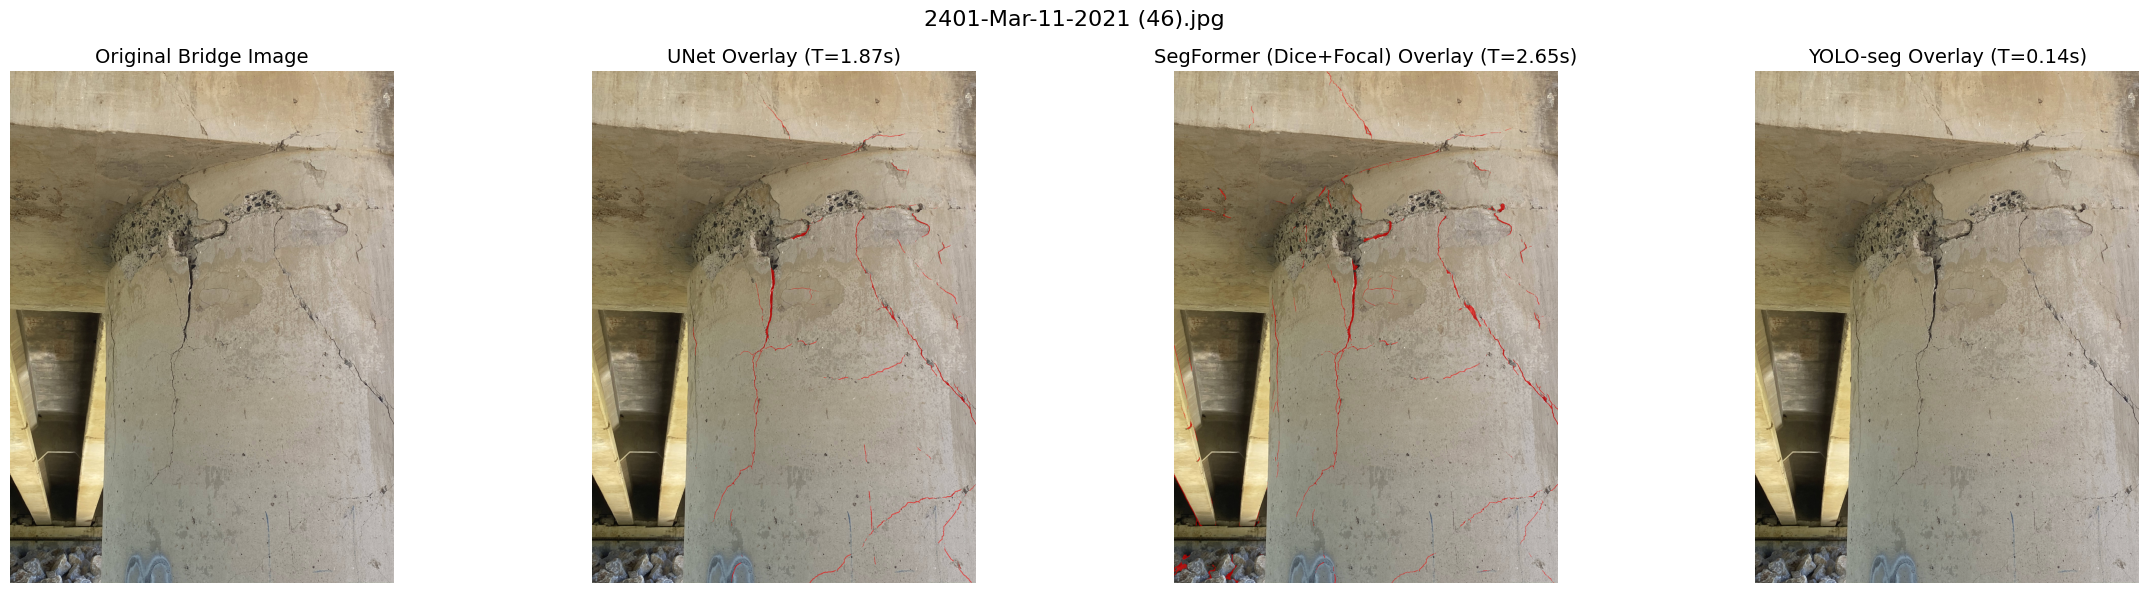

  2401-Mar-11-2021 (46).jpg                                    | UNet: 1.87s | SegFormer (Dice+Focal): 2.65s | YOLO: 0.14s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_2401-Mar-11-2021 (46).png


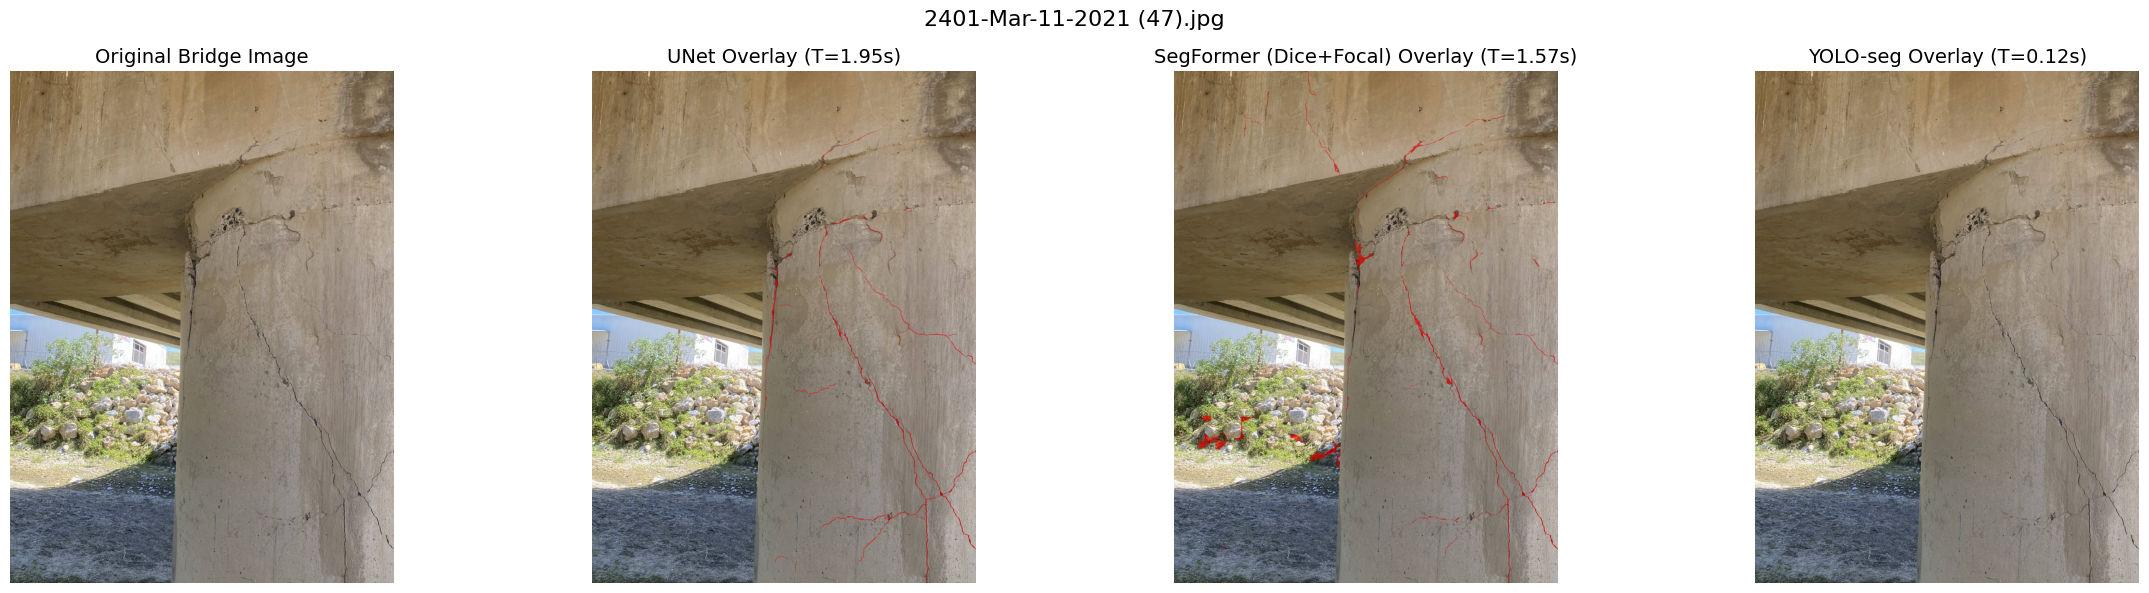

  2401-Mar-11-2021 (47).jpg                                    | UNet: 1.95s | SegFormer (Dice+Focal): 1.57s | YOLO: 0.12s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_2401-Mar-11-2021 (47).png


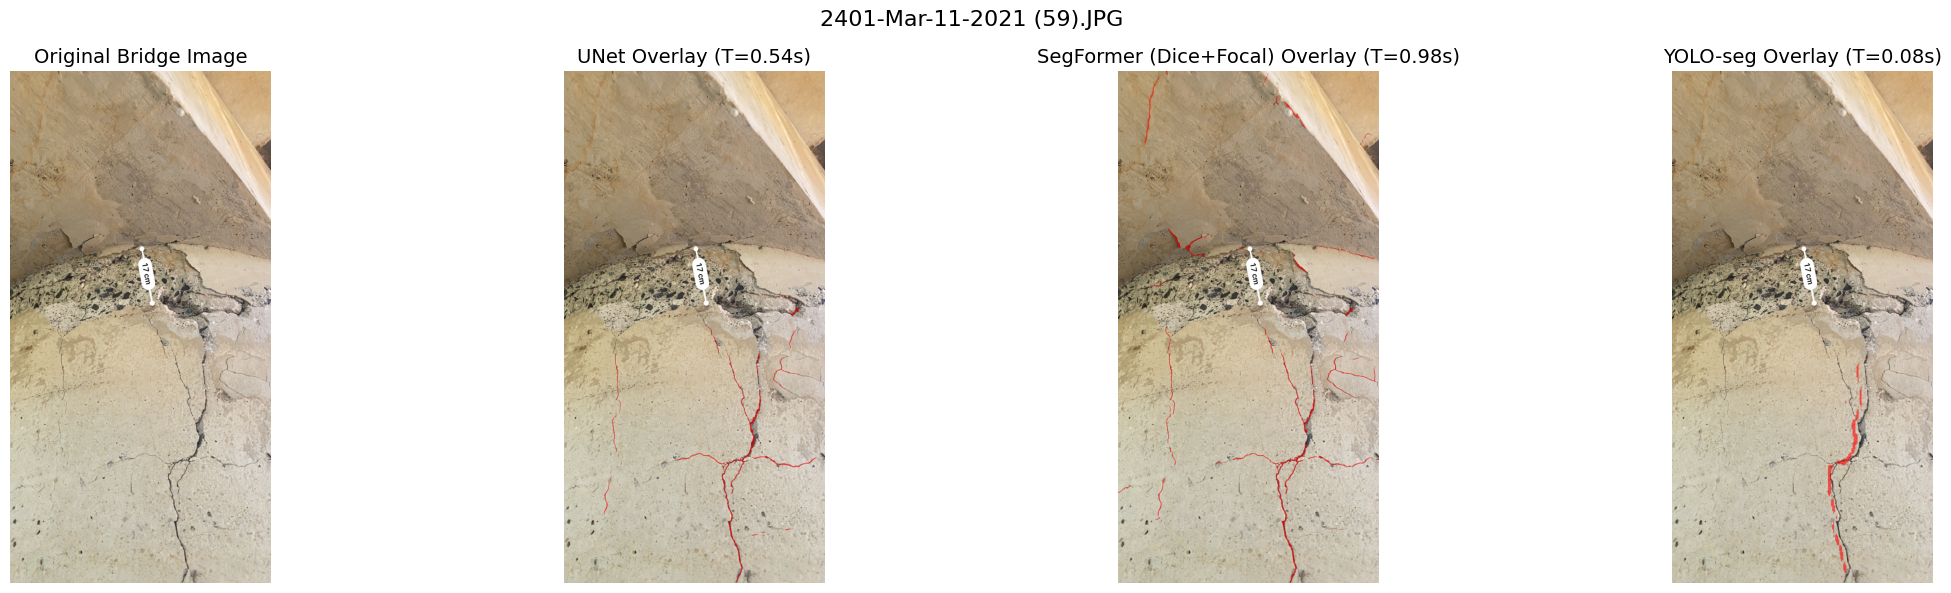

  2401-Mar-11-2021 (59).JPG                                    | UNet: 0.54s | SegFormer (Dice+Focal): 0.98s | YOLO: 0.08s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_2401-Mar-11-2021 (59).png


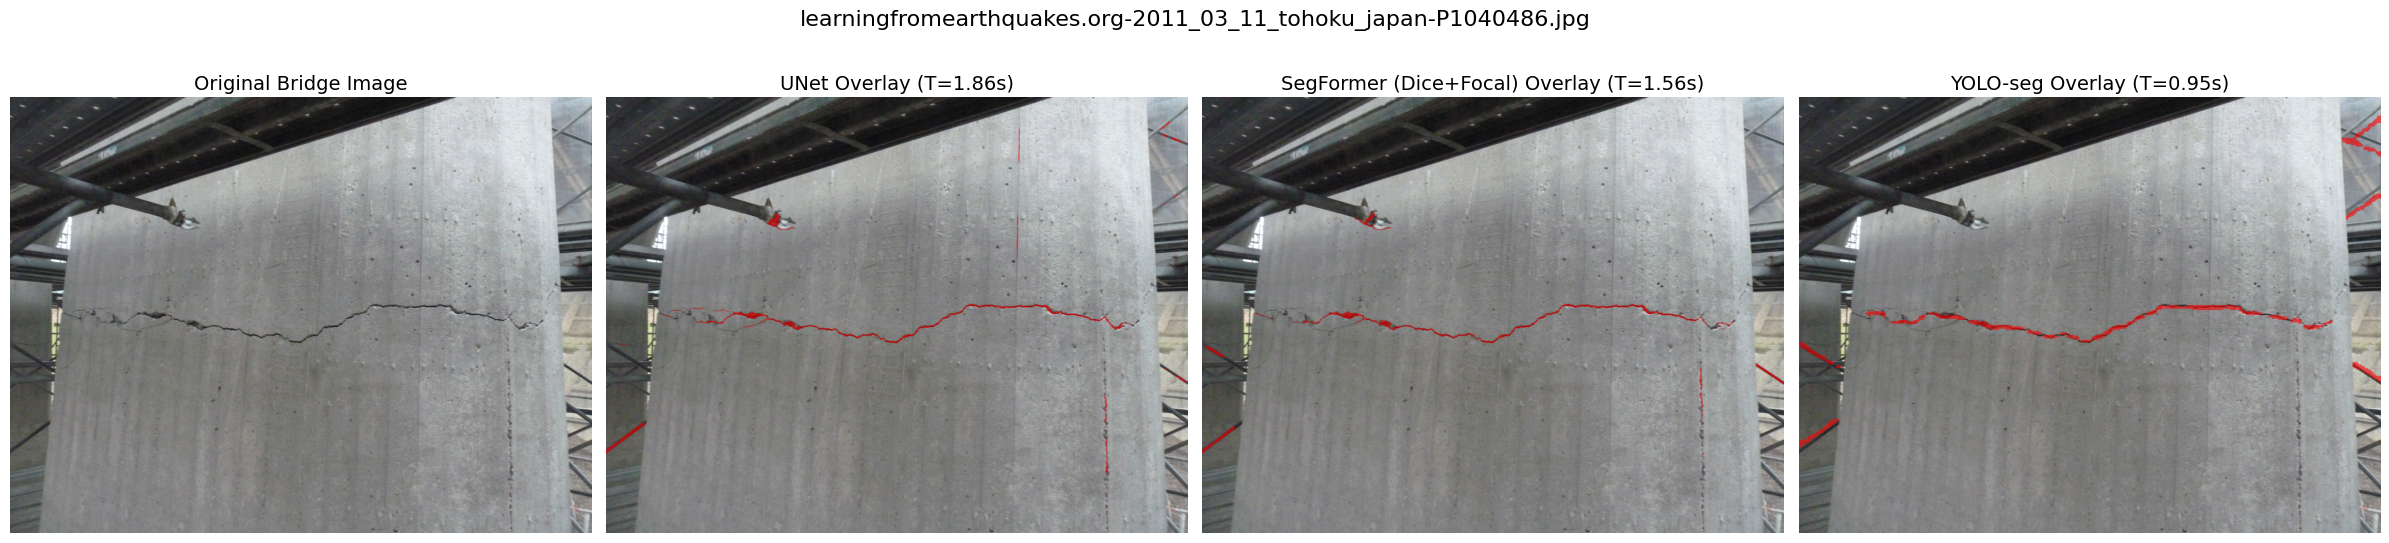

  learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.jpg | UNet: 1.86s | SegFormer (Dice+Focal): 1.56s | YOLO: 0.95s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.png


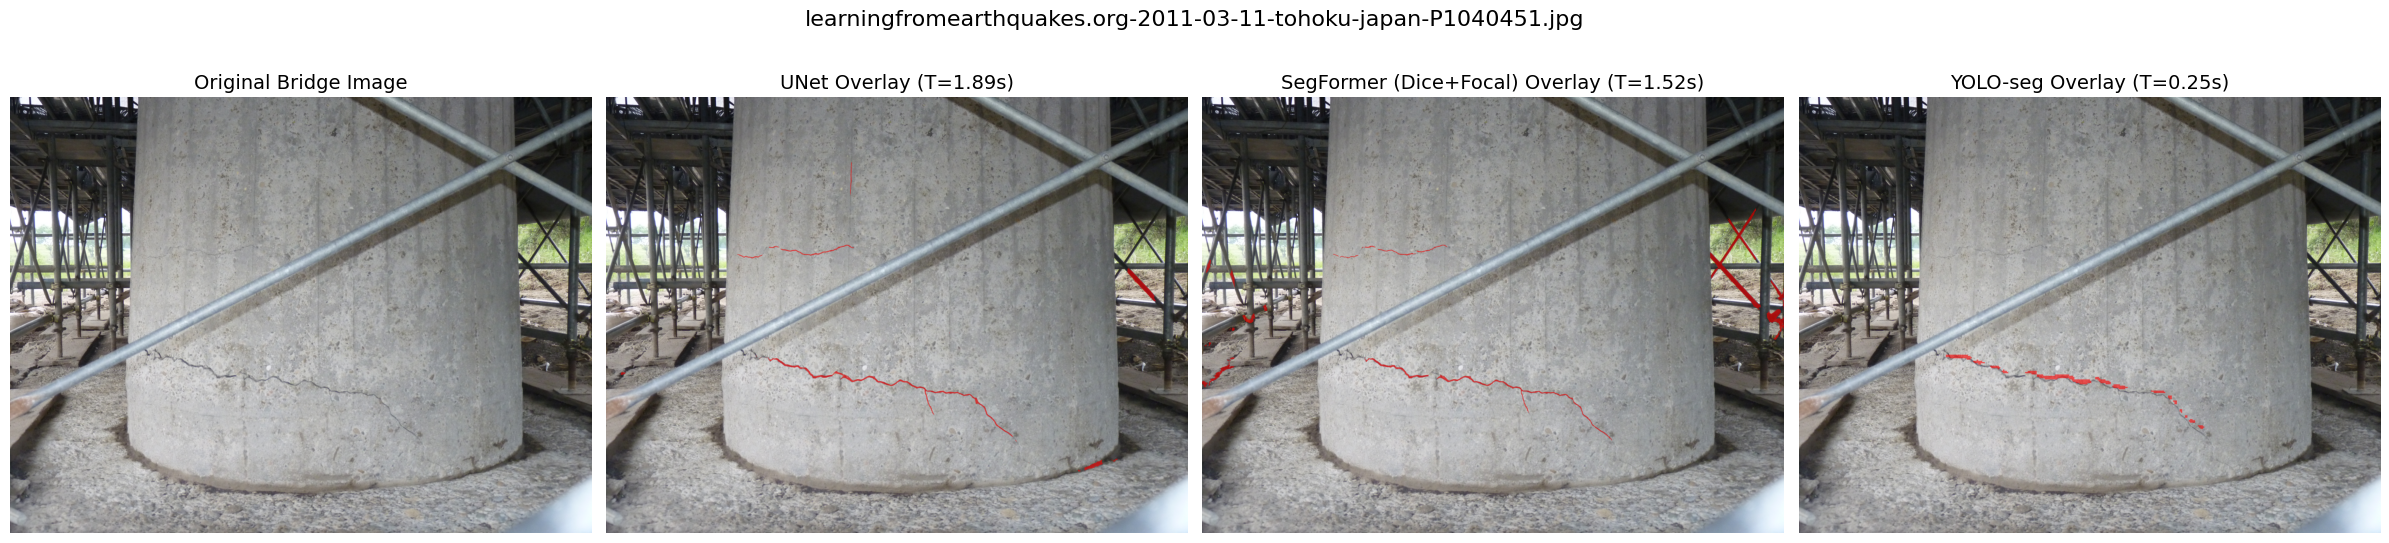

  learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.jpg | UNet: 1.89s | SegFormer (Dice+Focal): 1.52s | YOLO: 0.25s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.png


In [7]:
# ==============================================================================
# Model Overlay Visualization on Real Bridge Samples
# Shows: Original Image | UNet Overlay | SegFormer (Dice+Focal) Overlay | YOLO-seg Overlay
# ==============================================================================
import time
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Select comparison models from loaded_models
models_to_visualize = {
    "UNet": loaded_models.get("UNet (4 Datasets)", (None, None))[1]
            or loaded_models.get("UNet (NCCD-PF)", (None, None))[1],
    "SegFormer (Dice+Focal)": loaded_models.get("SegFormer (Dice+Focal)", (None, None))[1]
                             or loaded_models.get("SegFormer (4 Datasets)", (None, None))[1],
    "YOLO-seg": loaded_models.get("YOLO-seg (4 Datasets)", (None, None))[1],
}

# Validate selected models
for model_name, model_obj in models_to_visualize.items():
    if model_obj is None:
        raise ValueError(f"Required model '{model_name}' was not found in loaded_models.")

# 2. Batched GPU Patch Inference Configuration
PATCH_BATCH_SIZE = 16
USE_AMP = True
PATCH_SIZE = 448
STRIDE = 224
YOLO_CONF = 0.15

# GPU Warmup: run a dummy tensor through PyTorch models to eliminate one-time cuDNN compilation overhead
pytorch_models = [m for m in models_to_visualize.values() if isinstance(m, torch.nn.Module)]
warmup_gpu(
    pytorch_models,
    patch_batch_size=PATCH_BATCH_SIZE,
    patch_size=PATCH_SIZE,
    device=config.DEVICE,
    use_amp=USE_AMP,
)

# Output directory for saving comparison overlay figures
OUTPUT_DIR = config.BASE_DIR / "experimenting" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"\nGenerating 4-panel overlay visualizations for {len(bridge_samples)} bridge image(s)...\n")

# 3. Iterate through bridge samples and generate side-by-side overlay plots
overlay_results = []
for image_name, image_path, _, _ in bridge_samples:
    save_fig_path = OUTPUT_DIR / f"overlay_{Path(image_name).stem}.png"
    result = visualize_model_overlays(
        image=image_path,
        models=models_to_visualize,
        device=config.DEVICE,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        batch_size=PATCH_BATCH_SIZE,
        use_amp=USE_AMP,
        yolo_conf=YOLO_CONF,
        alpha=0.6,
        suptitle=image_name,
        save_path=save_fig_path,
        show=True,
    )
    t_unet = result["timings"].get("UNet", 0.0)
    t_seg = result["timings"].get("SegFormer (Dice+Focal)", 0.0)
    t_yolo = result["timings"].get("YOLO-seg", 0.0)
    print(f"  {image_name:<60} | UNet: {t_unet:.2f}s | SegFormer (Dice+Focal): {t_seg:.2f}s | YOLO: {t_yolo:.2f}s")
    print(f"    Saved figure to: {save_fig_path}")
    overlay_results.append(result)
